# Model-based RL: Dyna-Q

Every method so far is **model-free**: it learns values or a policy directly from real experience and never asks "what does the world do?". That gets expensive. Hopper took 300k real steps.

**Model-based RL** also learns a **model** of the environment: given `(s, a)`, what reward and next state come back. Once you have one, you can **plan**: imagine transitions with the model and learn from those too, without touching the real env.

**Dyna-Q** is the simplest version, and it's just Q-learning plus two lines:

1. **Learn the model:** after each real step, remember what happened: `model[(s, a)] = (r, s')`.
2. **Plan:** then replay `n` random remembered transitions through the same Q-learning update.

Same update rule, but each real step now buys `1 + n` updates. This is the replay-buffer idea from DQN/DDPG, seen from a different angle: here the buffer _is_ the model.


## Step 1: a maze, and plain Q-learning on it

The 3×4 gridworld is too small to show the difference, and it's stochastic (the move slips 20% of the time). Start with a bigger, **deterministic** maze: 6×9, walls in the way, start `S` on the left, goal `G` top right.

- reward: +1 for reaching `G`, 0 for every other step
- `γ = 0.95`, so a shorter path is worth more (`0.95^steps`)
- the shortest path is 14 steps


In [1]:
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

ROWS, COLS = 6, 9
WALLS = {(1, 2), (2, 2), (3, 2), (4, 5), (0, 7), (1, 7), (2, 7)}
START, GOAL = (2, 0), (0, 8)
DELTAS = [(-1, 0), (0, 1), (1, 0), (0, -1)]  # ^ > v <
ARROWS = "^>v<"


def step(s, a):
    """One move from state s = (row, col) with action a (index into DELTAS).

    Returns (next_state, reward, done):
      next_state: (row, col) after the move; hitting a wall or the edge leaves you in place
      reward:     1.0 if next_state is GOAL, else 0.0
      done:       True if next_state is GOAL (the episode ends)

    Deterministic: the same (s, a) always gives the same result.
    """
    r, c = s[0] + DELTAS[a][0], s[1] + DELTAS[a][1]
    ns = (r, c) if 0 <= r < ROWS and 0 <= c < COLS and (r, c) not in WALLS else s
    return ns, float(ns == GOAL), ns == GOAL


def show_maze(Q=None):
    """Walls, start and goal; with Q, the greedy action in every state it has a value for."""
    for r in range(ROWS):
        row = []
        for c in range(COLS):
            s = (r, c)
            if s in WALLS:
                row.append("#")
            elif s == GOAL:
                row.append("G")
            elif Q is not None and any(Q[(s, a)] for a in range(4)):
                row.append(ARROWS[max(range(4), key=lambda a: Q[(s, a)])])
            else:
                row.append("S" if s == START else ".")
        print(" ".join(row))
    print()


show_maze()

. . . . . . . # G
. . # . . . . # .
S . # . . . . # .
. . # . . . . . .
. . . . . # . . .
. . . . . . . . .



Q-learning as in `td_sarsa_qlearning.ipynb`, with one change: **ties are broken at random.** Every Q starts at 0, and `max` would always pick the first action (`^`), so the agent would bump into the top wall forever. Picking randomly among the tied best actions makes it a random walk until it first finds the goal.

The metric is **steps per episode**: how long it takes to reach `G`. It's averaged over 30 seeds, because one run is noisy.


In [2]:
def epsilon_greedy(Q, s, eps=0.1):
    """Returns an action index 0-3: random with probability eps, else a best one by Q."""
    if random.random() < eps:
        return random.randrange(4)
    qs = [Q[(s, a)] for a in range(4)]
    best = max(qs)
    return random.choice([a for a in range(4) if qs[a] == best])  # random tie-break


def q_update(Q, s, a, r, ns, done, alpha=0.1, gamma=0.95):
    """Moves Q[(s, a)] toward r + gamma * max_a' Q[(ns, a')], in place. Returns nothing."""
    target = r + gamma * max(Q[(ns, b)] for b in range(4)) * (not done)
    Q[(s, a)] += alpha * (target - Q[(s, a)])


def q_learning(n_episodes=50, seed=0):
    """Returns (Q, lengths): Q maps (state, action) -> value; lengths[i] is how many
    steps episode i took to reach the goal."""
    random.seed(seed)
    Q, lengths = defaultdict(float), []
    for _ in range(n_episodes):
        s, n = START, 0
        while True:
            a = epsilon_greedy(Q, s)
            ns, r, done = step(s, a)
            q_update(Q, s, a, r, ns, done)
            s, n = ns, n + 1
            if done:
                break
        lengths.append(n)
    return Q, lengths


runs = np.array([q_learning(seed=i)[1] for i in range(30)])
mean = runs.mean(0)
print("steps per episode, avg of 30 seeds:")
for ep in [1, 2, 3, 5, 10, 20, 30, 50]:
    print(f"  episode {ep:2d}: {mean[ep - 1]:5.0f}")
print(f"total real steps over 50 episodes: {runs.sum(1).mean():.0f}")

steps per episode, avg of 30 seeds:
  episode  1:   610
  episode  2:   877
  episode  3:   548
  episode  5:   303
  episode 10:   124
  episode 20:    52
  episode 30:    20
  episode 50:    19
total real steps over 50 episodes: 4987


In [3]:
runs.shape

(30, 50)

**The first episode is a long random walk** (about 600 steps), because no Q value is non-zero until the goal has been reached once. After that, the +1 has to creep backwards one state per visit: each update only looks one step ahead. It takes about 30 episodes (around 5000 real steps in total) before the path settles at about 20 steps. That's the 14-step shortest path, plus detours from ε = 0.1 exploration, plus a few states whose values haven't fully caught up.

That backward creep is the bottleneck. The agent already _knows_ how the maze connects (it has walked it), but it only updates a state when it happens to step there again.


## Step 2: Dyna-Q, remembering and replaying

After every real step:

1. **Model learning:** `model[(s, a)] = (r, s', done)`. The maze is deterministic, so one observation is the whole truth about that `(s, a)`.
2. **Planning:** `n` times, pick a random `(s, a)` seen before, look up its outcome in the model, and apply the **same** `q_update`.

With `n = 0` it's exactly the Q-learning above. With the same seed it makes the same random choices and gives the same curve, which the first check confirms.


In [4]:
def dyna_q(n_planning, n_episodes=50, seed=0):
    """Q-learning plus n_planning model replays per real step.
    Returns (Q, lengths), the same as q_learning."""
    random.seed(seed)
    Q, lengths = defaultdict(float), []
    model, seen = {}, []  # model: (s, a) -> (r, s', done); seen: its keys, for random.choice
    for _ in range(n_episodes):
        s, n = START, 0
        while True:
            a = epsilon_greedy(Q, s)
            ns, r, done = step(s, a)
            q_update(Q, s, a, r, ns, done)  # learn from the real step

            if (s, a) not in model:
                seen.append((s, a))
            model[(s, a)] = (r, ns, done)  # 1. learn the model
            for _ in range(n_planning):  # 2. plan: replay imagined steps
                ps, pa = random.choice(seen)
                q_update(Q, ps, pa, *model[(ps, pa)])

            s, n = ns, n + 1
            if done:
                break
        lengths.append(n)
    return Q, lengths


print("n=0 matches Q-learning:", dyna_q(0, seed=7)[1] == q_learning(seed=7)[1])

n=0 matches Q-learning: True


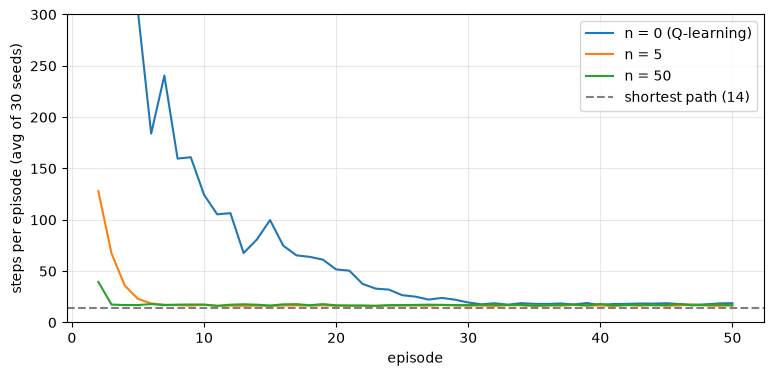

n =  0   episode 2:  877   episode 3:  548   episode 10:  124   total real steps:  4987
n =  5   episode 2:  128   episode 3:   67   episode 10:   17   total real steps:  1854
n = 50   episode 2:   40   episode 3:   17   episode 10:   17   total real steps:  1509


In [5]:
results = {n: np.array([dyna_q(n, seed=i)[1] for i in range(30)]) for n in [0, 5, 50]}

plt.figure(figsize=(9, 4))
for n, runs in results.items():
    plt.plot(range(2, 51), runs.mean(0)[1:], label=f"n = {n}" + (" (Q-learning)" if n == 0 else ""))
plt.axhline(14, color="gray", linestyle="--", label="shortest path (14)")
plt.xlabel("episode")
plt.ylabel("steps per episode (avg of 30 seeds)")
plt.ylim(0, 300)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for n, runs in results.items():
    m = runs.mean(0)
    print(
        f"n = {n:2d}   episode 2: {m[1]:4.0f}   episode 3: {m[2]:4.0f}   episode 10: {m[9]:4.0f}"
        f"   total real steps: {runs.sum(1).mean():5.0f}"
    )

Episode 1 is left out of the plot: every agent is still on its first random walk, with nothing to plan from yet.

**With 50 planning steps, the path is near-optimal by episode 3.** Plain Q-learning needs about 30 episodes. The total real experience drops from about 5000 steps to about 1500, and almost all of that is the first random walk.

**Why it works:** when the agent first reaches `G`, only the last state gets credit. Q-learning then needs a separate real visit to every earlier state to pass the +1 back. With the model, planning replays those earlier transitions immediately: within a few hundred imagined updates, the value spreads back along the whole remembered path. The real steps were spent on _discovering_ the maze. Planning does the bookkeeping for free.

**The cost moves to compute:** at `n = 50`, each real step does 51 updates. That's the core trade of model-based RL: real experience is expensive (a robot, a game server, a patient), computation is cheap.


## Step 3: a stochastic world breaks the "remember the last outcome" model

Back to the 3×4 gridworld from `tabular/`. A move goes where you meant **80%** of the time and slips sideways 10% each way. Each step costs -0.04, the top-right exit pays +1 and the one below it pays -1. `γ = 1`.

Dyna-Q's model stores **one** outcome per `(s, a)`: whatever happened last. In the maze that was the whole truth. Here it's a single sample, and planning replays that same sample 50 times per real step, as if the world always did that.

**The fix: count.** Keep a tally of every outcome seen for each `(s, a)`, and plan with an outcome drawn in proportion to the counts. After a few visits the tally is close to 80/10/10, so planning replays the world as it really is, on average.

**How to score it:** `value_iteration` knows the true transition probabilities, so it gives the exact optimal values `V*`. Track the RMS error between the learner's `max_a Q(s, a)` and `V*` over the 9 non-terminal states, against **real** steps. Episodes start in a random state (exploring starts), so every state gets visited.


In [6]:
import sys
from collections import Counter
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.append(str(root / "src" / "tabular"))

from common import value_iteration
from gridworld import STATES, TERMINALS, reset, sample_step, show

V_star = value_iteration()  # gamma = 1, exact: it uses the true probabilities
NONTERMINAL = [s for s in STATES if s not in TERMINALS]
show(V=V_star)

converged in 19 sweeps
+0.85  +0.91  +0.96  +1.00 
+0.80    ##   +0.70  -1.00 
+0.75  +0.70  +0.65  +0.43 



In [7]:
def dyna_grid(n_planning, model_kind="last", n_steps=3000, seed=0, every=100, track=(1, 2)):
    """Dyna-Q on the slippery gridworld, run for n_steps real steps.

    model_kind="last":  model[(s, a)] holds only the latest outcome, as in dyna_q
    model_kind="count": model[(s, a)] counts every outcome; planning samples one by count

    Returns (errs, tracked), both recorded every `every` real steps:
      errs:    RMS error of max_a Q(s, a) vs V*(s) over the non-terminal states
      tracked: max_a Q(track, a), one state's value estimate over time
    """
    random.seed(seed)
    Q, model, seen = defaultdict(float), {}, []
    errs, tracked = [], []
    v = lambda s: max(Q[(s, a)] for a in range(4))
    s = reset(explore=True)
    for t in range(1, n_steps + 1):
        a = epsilon_greedy(Q, s)
        ns, r, done = sample_step(s, a)
        q_update(Q, s, a, r, ns, done, gamma=1.0)

        if (s, a) not in model:
            seen.append((s, a))
            model[(s, a)] = Counter()
        if model_kind == "last":
            model[(s, a)] = Counter({(r, ns, done): 1})  # forget everything before
        else:
            model[(s, a)][(r, ns, done)] += 1  # keep the tally
        for _ in range(n_planning):
            ps, pa = random.choice(seen)
            outcomes = model[(ps, pa)]
            o = random.choices(list(outcomes), weights=list(outcomes.values()))[0]
            q_update(Q, ps, pa, *o, gamma=1.0)

        s = reset(explore=True) if done else ns
        if t % every == 0:
            errs.append(np.sqrt(np.mean([(v(x) - V_star[x]) ** 2 for x in NONTERMINAL])))
            tracked.append(v(track))
    return errs, tracked

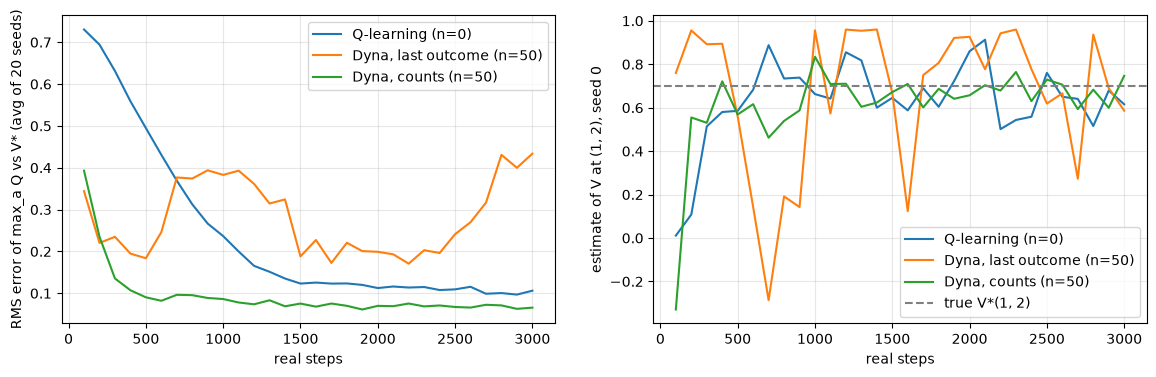

Q-learning (n=0)            RMS at 300 / 1000 / 3000 real steps: 0.631 / 0.237 / 0.106
Dyna, last outcome (n=50)   RMS at 300 / 1000 / 3000 real steps: 0.235 / 0.383 / 0.434
Dyna, counts (n=50)         RMS at 300 / 1000 / 3000 real steps: 0.135 / 0.086 / 0.066


In [8]:
configs = {
    "Q-learning (n=0)": dict(n_planning=0),
    "Dyna, last outcome (n=50)": dict(n_planning=50, model_kind="last"),
    "Dyna, counts (n=50)": dict(n_planning=50, model_kind="count"),
}
grid = {name: [dyna_grid(**cfg, seed=i) for i in range(20)] for name, cfg in configs.items()}

steps = np.arange(1, 31) * 100
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
for name, runs in grid.items():
    ax1.plot(steps, np.mean([e for e, _ in runs], axis=0), label=name)
    ax2.plot(steps, runs[0][1], label=name)  # seed 0 only: one run's estimate over time
ax1.set_ylabel("RMS error of max_a Q vs V* (avg of 20 seeds)")
ax2.axhline(V_star[(1, 2)], color="gray", linestyle="--", label="true V*(1, 2)")
ax2.set_ylabel("estimate of V at (1, 2), seed 0")
for ax in (ax1, ax2):
    ax.set_xlabel("real steps")
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

for name, runs in grid.items():
    e = np.mean([e for e, _ in runs], axis=0)
    print(f"{name:27s} RMS at 300 / 1000 / 3000 real steps: {e[2]:.3f} / {e[9]:.3f} / {e[-1]:.3f}")

**Remembering only the last outcome never converges.** It starts out fast: by about 500 real steps its error (0.18) is far below Q-learning's, because planning spreads values quickly. Then it stalls and bounces between about 0.17 and 0.43 for the rest of the run, and by the end it's worse than plain Q-learning (0.43 vs 0.11). More real data doesn't help, because the model never holds more than one sample per `(s, a)`.

**The right panel shows why.** State (1, 2) sits just left of the -1 exit, true value 0.70. Its last-outcome estimate jumps between about 0.95 and -0.29:

- Most of the time the last move went where it was meant (80% chance). Planning then treats the move as 100% reliable, and the estimate overshoots towards 0.95.
- When the last move slipped (into the pit, or into a wall), planning replays that slip 50 times per step as if it always happens, and the estimate crashes.

The overshoots are small and the crashes are big, so on average the values come out **too low**. In a 10-seed check, the mean error was -0.39.

**Counting fixes it.** It has the lowest error at every point (0.14 → 0.09 → 0.07), and its estimate of (1, 2) settles near 0.70. Each planning step samples from the tally, so on average it replays the real 80/10/10 odds.

**Plain Q-learning is slower but honest.** Each real step is a fresh sample, and α = 0.1 averages over them. Its leftover wobble (about ±0.2 at (1, 2)) is that averaging still going on.

**The lesson:** a model has to represent what the world can do, not just what it did last time. Planning amplifies the model's errors: 50 updates per real step means 50 times the trust in whatever the model says.


## Step 4: a changing world, and Dyna-Q+

Even a perfect model goes stale if the world changes. Planning then keeps replaying the old world, very confidently.

**The shortcut maze:** a long wall on row 3 leaves only a gap at the far left, so the path from `S` to `G` is a 16-step detour. After 3000 steps, a second gap opens at the far **right**, making a 10-step shortcut.

Why should plain Dyna-Q have trouble? Its model says "going up from under the right end of the wall bumps into it". That was true for 3000 steps, nothing will make the agent retry it except a lucky ε step at exactly that spot, and planning keeps reinforcing the old detour 50 times per real step.

(The opposite change, where the known path gets **blocked**, fixes itself: the agent walks into the new wall, its model updates, and planning reroutes. A path that *opens* is the hard case, because nothing forces the agent to look.)

**Dyna-Q+** adds curiosity about the old parts of the model. In planning only, each transition's reward gets a bonus that grows with how long ago it was last tried for real:

    planning reward = r + κ·√τ        τ = real steps since (s, a) was last taken, κ = 0.001

A transition untried for 3000 steps earns `0.001·√3000 ≈ 0.05` extra per replay. That is enough to make planning value "go check that spot", so the agent eventually acts on it and discovers the change. One more detail: for every visited state, actions never tried enter the model as "stay put, reward 0", so they can collect the bonus too.

The metric is the textbook one: **cumulative reward** (the number of times `G` was reached) over 6000 real steps. Episodes restart at `S` after each goal, and the slope is the rate of reaching it. With κ = 0 the function below is exactly Dyna-Q.

In [9]:
import math

SC_START = (5, 3)
WALL_BEFORE = {(3, c) for c in range(1, 9)}  # only the left gap (3, 0)
WALL_AFTER = {(3, c) for c in range(1, 8)}  # and now the right one (3, 8) too


def show_walls(walls):
    for r in range(ROWS):
        row = []
        for c in range(COLS):
            s = (r, c)
            row.append("#" if s in walls else "G" if s == GOAL else "S" if s == SC_START else ".")
        print(" ".join(row))
    print()


def sc_step(s, a, walls):
    """Like step, with the walls passed in. Returns (next_state, reward, done)."""
    r, c = s[0] + DELTAS[a][0], s[1] + DELTAS[a][1]
    ns = (r, c) if 0 <= r < ROWS and 0 <= c < COLS and (r, c) not in walls else s
    return ns, float(ns == GOAL), ns == GOAL


print("steps 1-3000:")
show_walls(WALL_BEFORE)
print("steps 3001-6000:")
show_walls(WALL_AFTER)

steps 1-3000:
. . . . . . . . G
. . . . . . . . .
. . . . . . . . .
. # # # # # # # #
. . . . . . . . .
. . . S . . . . .

steps 3001-6000:
. . . . . . . . G
. . . . . . . . .
. . . . . . . . .
. # # # # # # # .
. . . . . . . . .
. . . S . . . . .



In [10]:
def dyna_plus(kappa, n_planning=50, n_steps=6000, change_at=3000, seed=0):
    """Dyna-Q (kappa=0) or Dyna-Q+ (kappa>0) on the shortcut maze, for n_steps real steps.

    Returns (cum, Q): cum[t] is how many times G was reached in the first t+1 steps.
    """
    random.seed(seed)
    Q, model, seen = defaultdict(float), {}, []
    last_tried = {}  # (s, a) -> real step it was last taken
    cum, goals = [], 0
    s = SC_START
    for t in range(1, n_steps + 1):
        walls = WALL_BEFORE if t <= change_at else WALL_AFTER
        a = epsilon_greedy(Q, s)
        ns, r, done = sc_step(s, a, walls)
        q_update(Q, s, a, r, ns, done)

        if kappa and not any((s, b) in model for b in range(4)):
            for b in range(4):  # first visit: untried actions modeled as "stay, reward 0"
                model[(s, b)] = (0.0, s, False)
                last_tried[(s, b)] = 0
                seen.append((s, b))
        if (s, a) not in model:
            seen.append((s, a))
        model[(s, a)] = (r, ns, done)
        last_tried[(s, a)] = t

        for _ in range(n_planning):
            ps, pa = random.choice(seen)
            pr, pns, pdone = model[(ps, pa)]
            bonus = kappa * math.sqrt(t - last_tried[(ps, pa)])  # the longer untried, the bigger
            q_update(Q, ps, pa, pr + bonus, pns, pdone)

        goals += r
        cum.append(goals)
        s = SC_START if done else ns
    return cum, Q

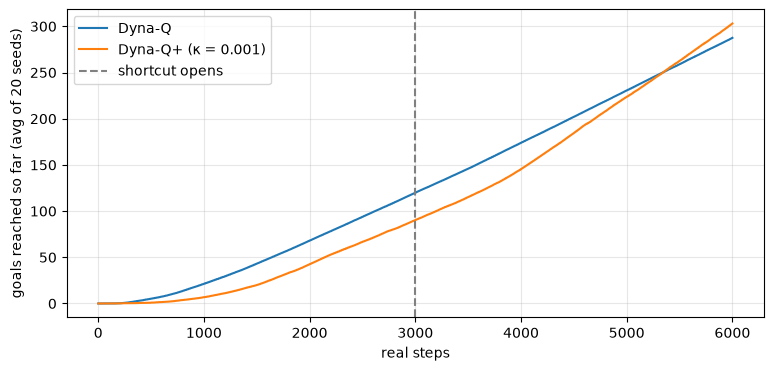

Dyna-Q               goals in steps 1-3000: 120.0   3001-6000: 167.6   using the shortcut by the end: 1/20 seeds
Dyna-Q+ (κ = 0.001)  goals in steps 1-3000:  90.4   3001-6000: 212.7   using the shortcut by the end: 20/20 seeds


In [11]:
sc = {
    "Dyna-Q": np.array([dyna_plus(0, seed=i)[0] for i in range(20)]),
    "Dyna-Q+ (κ = 0.001)": np.array([dyna_plus(1e-3, seed=i)[0] for i in range(20)]),
}

plt.figure(figsize=(9, 4))
for name, cum in sc.items():
    plt.plot(np.arange(1, 6001), cum.mean(0), label=name)
plt.axvline(3000, color="gray", linestyle="--", label="shortcut opens")
plt.xlabel("real steps")
plt.ylabel("goals reached so far (avg of 20 seeds)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for name, cum in sc.items():
    before, after = cum[:, 2999], cum[:, -1] - cum[:, 2999]
    # goals in the last 1000 steps: about 55 on the detour, 73-86 on the shortcut
    found = (cum[:, -1] - cum[:, -1001] > 65).sum()
    print(
        f"{name:20s} goals in steps 1-3000: {before.mean():5.1f}   3001-6000: {after.mean():5.1f}"
        f"   using the shortcut by the end: {found}/20 seeds"
    )

**Dyna-Q almost never finds the shortcut:** 1 seed in 20. Its slope barely changes after step 3000, and the other 19 seeds keep taking the detour (about 55 goals per 1000 steps) until the end. Its model is *confidently wrong* about one spot, and nothing in the algorithm questions it.

**Dyna-Q+ finds it in 20 of 20 seeds.** Its slope steepens a few hundred steps after the change, and it overtakes Dyna-Q's running total around step 5300. Over the second half it reaches the goal 213 times vs 168.

**The curiosity isn't free:**

- **Before the change** there's nothing new to find, but the bonus still sends the agent poking at old transitions. It reaches the goal 90 times vs Dyna-Q's 120, which is why its curve starts out lower.
- **After finding the shortcut** it keeps exploring: 73–85 goals per 1000 steps, while Dyna-Q's one lucky seed that found the shortcut got 86.

κ sets that trade: bigger means faster discovery and a higher exploration tax. It's the same explore/exploit dilemma as ε-greedy, aimed more cleverly: at the parts of the model most likely to be out of date, rather than at random.